# Experiment 7: Mamdani Fuzzy Inference System

**Aim:** To implement a simple Mamdani Fuzzy Inference System using Python and scikit-fuzzy.

## Theory
Mamdani FIS steps:
1. **Fuzzification** of crisp inputs.
2. **Rule evaluation** (AND = min).
3. **Implication** (clip the output MF at rule strength).
4. **Aggregation** of all rule outputs (max).
5. **Defuzzification** (centroid).

Problem: *Tipping problem*: compute tip % from service quality and food quality.

### Step 1: Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
%matplotlib inline

### Step 2: Define inputs (antecedents) and output (consequent)

In [2]:
service = ctrl.Antecedent(np.arange(0, 11, 1), 'service')
food    = ctrl.Antecedent(np.arange(0, 11, 1), 'food')
tip     = ctrl.Consequent(np.arange(0, 26, 1), 'tip')

### Step 3: Membership functions

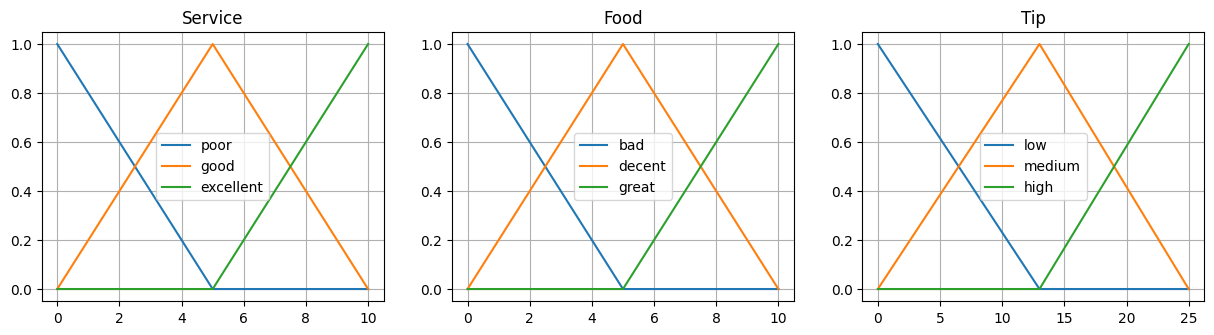

In [3]:
service['poor']    = fuzz.trimf(service.universe, [0, 0, 5])
service['good']    = fuzz.trimf(service.universe, [0, 5, 10])
service['excellent'] = fuzz.trimf(service.universe, [5, 10, 10])

food['bad']     = fuzz.trimf(food.universe, [0, 0, 5])
food['decent']  = fuzz.trimf(food.universe, [0, 5, 10])
food['great']   = fuzz.trimf(food.universe, [5, 10, 10])

tip['low']    = fuzz.trimf(tip.universe, [0, 0, 13])
tip['medium'] = fuzz.trimf(tip.universe, [0, 13, 25])
tip['high']   = fuzz.trimf(tip.universe, [13, 25, 25])

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for var, a, name in zip([service, food, tip], ax, ['Service', 'Food', 'Tip']):
    for term in var.terms:
        a.plot(var.universe, var[term].mf, label=term)
    a.set_title(name); a.legend(); a.grid(True)
plt.show()

### Step 4: Rule base

In [4]:
rule1 = ctrl.Rule(service['poor'] | food['bad'],        tip['low'])
rule2 = ctrl.Rule(service['good'],                      tip['medium'])
rule3 = ctrl.Rule(service['excellent'] | food['great'], tip['high'])
rules = [rule1, rule2, rule3]
for r in rules: print(r)

IF service[poor] OR food[bad] THEN tip[low]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF service[good] THEN tip[medium]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF service[excellent] OR food[great] THEN tip[high]
	AND aggregation function : fmin
	OR aggregation function  : fmax


### Step 5: Build control system and simulate

In [5]:
tipping_ctrl = ctrl.ControlSystem(rules)
tipping = ctrl.ControlSystemSimulation(tipping_ctrl)

tipping.input['service'] = 6.5
tipping.input['food']    = 9.0
tipping.compute()
print(f"Recommended tip = {tipping.output['tip']:.2f} %")

Recommended tip = 14.65 %


### Step 6: Visualise aggregated output and the centroid

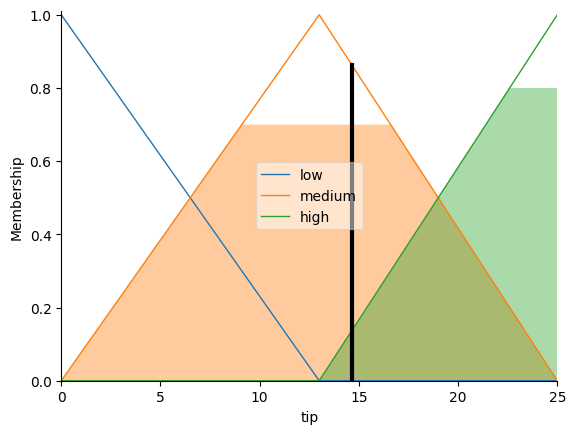

In [6]:
tip.view(sim=tipping)
plt.show()

### Step 7: Test several inputs

In [7]:
for s, f in [(1, 1), (5, 5), (8, 3), (10, 10)]:
    sim = ctrl.ControlSystemSimulation(tipping_ctrl)
    sim.input['service'] = s; sim.input['food'] = f
    sim.compute()
    print(f"service={s:>2}, food={f:>2}  ->  tip = {sim.output['tip']:.2f} %")

service= 1, food= 1  ->  tip = 8.19 %
service= 5, food= 5  ->  tip = 12.67 %
service= 8, food= 3  ->  tip = 13.52 %
service=10, food=10  ->  tip = 21.00 %


### Step 8: Control surface

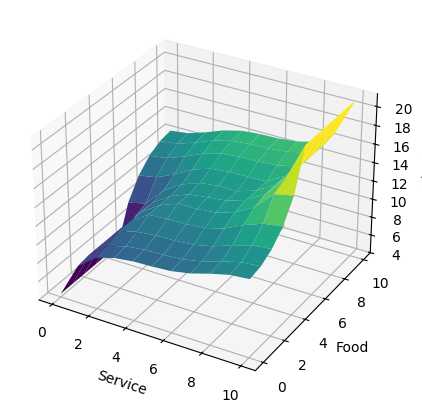

In [8]:
from mpl_toolkits.mplot3d import Axes3D
xs = np.arange(0, 11, 1); ys = np.arange(0, 11, 1)
X, Y = np.meshgrid(xs, ys); Z = np.zeros_like(X, dtype=float)
sim = ctrl.ControlSystemSimulation(tipping_ctrl)
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        sim.input['service'] = X[i, j]; sim.input['food'] = Y[i, j]
        sim.compute(); Z[i, j] = sim.output['tip']
fig = plt.figure(figsize=(7, 5)); ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis')
ax.set_xlabel('Service'); ax.set_ylabel('Food'); ax.set_zlabel('Tip %'); plt.show()

## Conclusion
A Mamdani FIS was implemented using scikit-fuzzy. Fuzzy inputs, rules, aggregation and centroid defuzzification gave a smooth crisp tip value for each combination of service and food quality.